### Running the notebook                                                                                  
Install the environment with `uv sync`, then download the data as described in [docs/setup.md](../docs/setup.md); Then run all cells.                             

# Project: Land Surface Temperature Monitoring


This project's goal is to create a lag response model for drought detection in the Luxembourgish Region.

We will be using the following indices as input for our model:
- TRI (Temperature Rise Index): how much the land surface warms in the morning (LST 3.5 h after sunrise minus 1.5 h after, in K); dry crops warm faster
- SPI (Standardized Precipitation Index): change in rainfall compared to usual rainfall
- VCI (Vegetation Condition Index): compares current greenness of vegetation to worst and best year

Models will predict the change in VCI from t to t+1.
Their input will be the x timesteps beforehand (default: 3).

We use our data on the Luxembourg Region [5.3, 49.2, 6.8, 50.3] (set in src/esa_lstm/config.py)

## Datasets
- MSG LST: Land surface temperature from a European geostationary weather satellite that watches the same area every 15 minutes
- ERA5-Land: A model-based reconstruction of past weather (including rainfall) going back to 1950
- MODIS NDVI: A NASA satellite measure of how green the vegetation is, available every 16 days at 250 m since 2000.
- ESA WorldCover: A 10 m global map of land types that shows which pixels are cropland
- ECOSTRESS: A NASA thermal sensor on the Space Station that captures very detailed (70 m) snapshots of plant temperature and water stress, though at a different time of day on each pass.
- EDO CDI: The EU’s official drought map, which combines rainfall, soil moisture and vegetation data into Watch, Warning and Alert levels every 10 days.

Downloading the datasets is explained in setup.md

### What they are used for:
- MSG LST: for TRI
- ERA5-Land: calculate SPI
- MODIS NDVI: NDVI is used to calculate VCI
- ESA WorldCover: filtering out non-cropland cells
- ECOSTRESS: for validation, so we can check high TRI -> high plant stress
- EDO CDI: for validation, low VCI => Alert

### Setting up input data

#### Step 1:
1) Load data all the datasets.
2) Limit data to selected box (in this case Luxembourg Region)

Notes:
- MSG LST uses NaN pixel values on cloudy pixels; only morning times are used
- MODIS-NDVI unreliable pixel data is set to NaN

In [2]:
from esa_lstm.config import CROP_FRACTION_MIN, VCI_MIN_VISIBLE
from esa_lstm.preprocess import grid, indices, load, windows

# The loaders already cut each dataset to the study box
lst = load.load_msg_lst()["LST"]          # (time, lat, lon) °C, morning slots, NaN = cloud
ndvi = load.load_modis_ndvi()             # (time, lat, lon) 250 m, reliability > 1 -> NaN
precip = load.load_era5_precip("daily")   # (time, lat, lon) 0.1°, mm per day
classes = load.load_worldcover()          # (lat, lon) 10 m land-cover classes

for name, da in {"MSG LST": lst, "MODIS NDVI": ndvi, "ERA5-Land": precip, "WorldCover": classes}.items():
    print(f"{name:11} {dict(da.sizes)}")

MSG LST     {'time': 19006, 'lat': 23, 'lon': 31}
MODIS NDVI  {'time': 595, 'lat': 529, 'lon': 721}
ERA5-Land   {'time': 16436, 'lat': 12, 'lon': 16}
WorldCover  {'lat': 14401, 'lon': 19201}


#### Step 2:
Process the indices (TRI, VCI, SPI) for each pixel per dataset

Notes:
- TRI in K
- VCI the lower the worse; uses 2000-2025 as study years
- SPI 1991–2020 as study years

In [3]:
starts = windows.season_windows()   # 16-day windows starting Apr–Sep, 2018–2025

tri_daily = indices.daily_lst_rise(lst)               # K, per pixel and clear morning
vci_250m = indices.vci(ndvi)                          # 0–100, per 250 m pixel and image
spi_native = windows.spi_per_window(precip, starts)   # SPI-1 on the 0.1° ERA5 grid (30 days ending on each window's last day)

#### Step 3:
Harmonise the different grids --> to one grid (the one from MSG 0.05°)
- fix grid by TRI
- VCI is finer so weighted average of cropland share
- SPI is coarser so we use bilinear interpolation

Notes:
- A cell is considered cropland if cropland share is at least 50%
- if less than 50% of cropland in a cell is clear, we set its VCI to NaN

In [4]:
target = grid.target_grid()   # the MSG grid, so TRI needs no change
assert (tri_daily.lat.values == target.lat.values).all() and (tri_daily.lon.values == target.lon.values).all()

crop_share = grid.cropland_share(classes, target)
crop_mask = crop_share >= CROP_FRACTION_MIN

crop_250m = grid.cropland_share(classes, ndvi)   # cropland weight of each MODIS pixel
vci_grid = grid.block_mean(vci_250m, target, weights=crop_250m)
visible = grid.block_mean(ndvi.notnull().astype("float32"), target, weights=crop_250m)
vci_grid = vci_grid.where(visible >= VCI_MIN_VISIBLE)   # drop cells whose cropland is < 50 % clear

spi_grid = grid.interpolate(spi_native, target)   # bilinear
print(f"cropland cells: {int(crop_mask.sum())} of {crop_mask.size}")

cropland cells: 58 of 713


#### Step 4:
- divide into timesteps of 16-days (= same as MODIS NDVI period, so VCI needs no interpolation --> no leakage)
- SPI-1: of the 30 days ending on the window's last day (so no data leakage)
- TRI: means of clear mornings during the window (minimum 1); Raw TRI is used

In [5]:
tri = windows.mean_per_window(tri_daily, starts)   # mean of clear mornings, 1 is enough
vci = vci_grid.reindex(time=starts)                # one MODIS image per window; a missing one stays NaN
spi1 = spi_grid                                     # already per window (Step 2)
print({name: dict(da.sizes) for name, da in {"tri": tri, "vci": vci, "spi1": spi1}.items()})

{'tri': {'time': 96, 'lat': 23, 'lon': 31}, 'vci': {'time': 96, 'lat': 23, 'lon': 31}, 'spi1': {'time': 96, 'lat': 23, 'lon': 31}}


#### Step 5:
- Flatten the data into a table
- keep only cropland cells (50%)
- columns are cell_id, lat, lon, window_start, vci, tri, spi1
- keep NaN values (cloudy)

In [6]:
table = windows.to_table(vci, tri, spi1, crop_mask)
print(table.isna().mean().round(3))   # share of missing values per column
table.head()

cell_id         0.000
lat             0.000
lon             0.000
window_start    0.000
vci             0.052
tri             0.109
spi1            0.000
dtype: float64


,cell_id,lat,lon,window_start,vci,tri,spi1
0,49.20_5.30,49.2,5.3,2018-04-07,75.093010,8.847240,0.275397
1,49.20_5.30,49.2,5.3,2018-04-23,56.412647,7.018948,-0.466434
2,49.20_5.30,49.2,5.3,2018-05-09,71.411423,6.836552,0.392056
3,49.20_5.30,49.2,5.3,2018-05-25,69.739059,5.440383,0.444142
4,49.20_5.30,49.2,5.3,2018-06-10,37.380161,6.911869,0.338913


#### Step 6:
Now we can build the labeled X, y data
- X has 14 columns: VCI, TRI and SPI-1 at t-2, t-1 and t (9 columns), plus 5 "missing" flags for TRI at t-2, t-1, t and VCI at t-2, t-1
- y is VCI(t+1) − VCI(t), the change in VCI over the next window
- rows are only kept if t-2, t-1 and t+1 exist in the same cell and the same year, and y is not NaN
- total: 3826 rows

In [7]:
from esa_lstm.models import rows

X, y, meta = rows.build_rows(table)   # inputs at t-2, t-1, t (+ missing flags), target: VCI change t -> t+1
print(f"{len(X)} rows, {X.shape[1]} input columns")

3826 rows, 14 input columns


### Models

Two simple models are considered:
- Linear Regression
- Gradient Boosted Machine (GBM)

Missing data is handled differently for each one (linear fills missing inputs with the training mean; GBM handles them natively)

Model settings come from `configs/<model>.yaml`

In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from esa_lstm import plotting
from esa_lstm.config import ROOT
from esa_lstm.models import evaluate, get_model, plots, split
from esa_lstm.models.config import load_config

plotting.use_style()

MODELS = ["linear", "gbm"]   # one config per model in configs/; add a name here to add a model
settings = {name: load_config(ROOT / "configs" / f"{name}.yaml") for name in MODELS}


def new_model(name):
    """A new, untrained model with the settings of configs/<name>.yaml."""
    return get_model(settings[name]["model"], **settings[name]["params"])


predictions = {name: evaluate.predictions_table(X, y, meta, split.predict_held_out(lambda: new_model(name), X, y, meta))
               for name in MODELS}
print(f"{len(predictions[MODELS[0]])} of {len(X)} rows predicted per model")

3565 of 3826 rows predicted per model


#### Comparison

Baseline: no change predicts that t+1 is equal to t.

For each year train the models on the rest of the data and use that year as the test set we evaluate them on using RMSE (lower is better).
"all" is the RMSE of all held-out predictions pooled across the 8 seasons.  

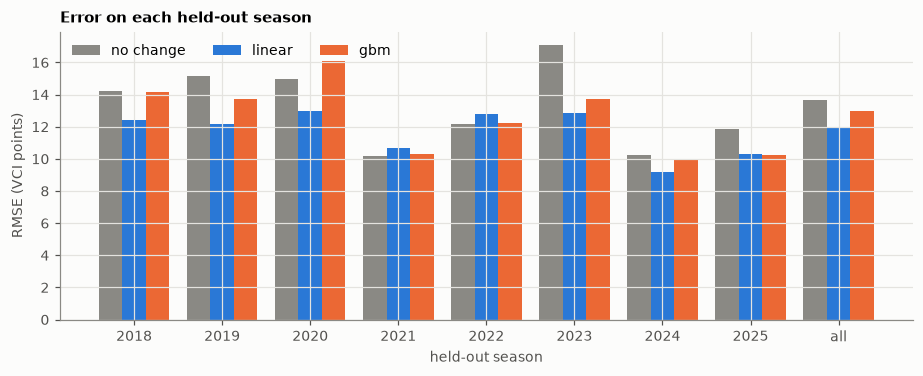

held_out_year,2018,2019,2020,2021,2022,2023,2024,2025,all
no change,14.2,15.2,15.0,10.2,12.2,17.1,10.3,11.8,13.7
linear,12.5,12.2,13.0,10.6,12.8,12.8,9.2,10.3,11.9
gbm,14.1,13.7,16.1,10.3,12.3,13.7,9.9,10.3,13.0


In [9]:
errors = pd.DataFrame({"no change": evaluate.errors(predictions[MODELS[0]])["baseline"]}
                      | {name: evaluate.errors(p)["model"] for name, p in predictions.items()})

colours = [plotting.MUTED] + plotting.SERIES[:len(MODELS)]
width = 0.8 / len(errors.columns)
x = np.arange(len(errors))
fig, ax = plt.subplots(figsize=(10, 3.4))
for i, (name, colour) in enumerate(zip(errors.columns, colours)):
    ax.bar(x + (i - (len(errors.columns) - 1) / 2) * width, errors[name], width, color=colour, label=name)
ax.set_xticks(x, errors.index)
ax.set(xlabel="held-out season", ylabel="RMSE (VCI points)", title="Error on each held-out season")
ax.legend(ncols=len(errors.columns), loc="upper left")
plt.show()

errors.round(1).T

- **Linear** beats no change overall (11.9 against 13.7 VCI points, 13 % lower) and in 6 of the 8 seasons. It is slightly worse in 2021 (10.6 against 10.2) and 2022 (12.8 against 12.2). Its largest gain is in 2023 (12.8 against 17.1).
- **GBM** is only a little better than no change overall (13.0) and better in 5 of the 8 seasons. It is clearly worse in 2020 (16.1 against 15.0); in 2021 and 2022 it is within 0.1 of no change.

#### Results per model

`show_model` draws four figures for one model:

1. **Over the season:** cropland-mean VCI per target window, actual vs predicted vs no change, one panel per season.
2. **In space:** RMSE per cell, the model next to no change on the same colour scale (darker = larger error).
3. **Driest window:** actual vs predicted VCI per cell on the target window with the lowest cropland-mean actual VCI.
4. **Importance:** how much the model relies on each input, from the model trained once on all seasons (the version `run.py` saves).

In [10]:
def show_model(name):
    """The four figures of one model, then the numbers the text below them uses."""
    p = predictions[name]
    plots.timeseries(p)
    plots.skill_map(p)
    date = pd.Timestamp(plots.driest_date(p))
    plots.date_map(p, date)
    model = new_model(name).fit(X, y)  # all seasons
    importance = model.importance(X, y)
    plots.importance(importance, name)

    seasons = errors.drop("all")
    means = p.groupby("target_date")[["vci_actual", "vci_predicted", "vci_baseline"]].mean()
    cells = p.groupby("cell_id")
    cell_model = cells.apply(lambda c: evaluate.rmse(c["vci_actual"], c["vci_predicted"]))
    cell_baseline = cells.apply(lambda c: evaluate.rmse(c["vci_actual"], c["vci_baseline"]))
    day = p[p["target_date"] == date]
    print(f"RMSE over all seasons: {name} {errors.loc['all', name]:.1f}, no change {errors.loc['all', 'no change']:.1f}; "
          f"better in {int((seasons[name] < seasons['no change']).sum())} of {len(seasons)} seasons")
    print(f"cropland-mean RMSE: {name} {evaluate.rmse(means['vci_actual'], means['vci_predicted']):.1f}, "
          f"no change {evaluate.rmse(means['vci_actual'], means['vci_baseline']):.1f}")
    print(f"better than no change in {int((cell_model < cell_baseline).sum())} of {len(cell_model)} cells; "
          f"RMSE per cell {cell_model.min():.1f}–{cell_model.max():.1f} (no change {cell_baseline.min():.1f}–{cell_baseline.max():.1f})")
    print(f"driest window {date:%Y-%m-%d}: cropland mean actual {day['vci_actual'].mean():.1f}, "
          f"{name} {day['vci_predicted'].mean():.1f}, no change {day['vci_baseline'].mean():.1f}")
    print("largest importance:", ", ".join(f"{c} {v:+.1f}" for c, v in importance.loc[importance.abs().nlargest(3).index].items()))

#### Linear regression

Missing inputs are filled with the training mean, every input is scaled to mean 0 and standard deviation 1, then a linear regression is fitted. Importance: the weight of each scaled input (VCI change per standard deviation of the input; orange = negative).

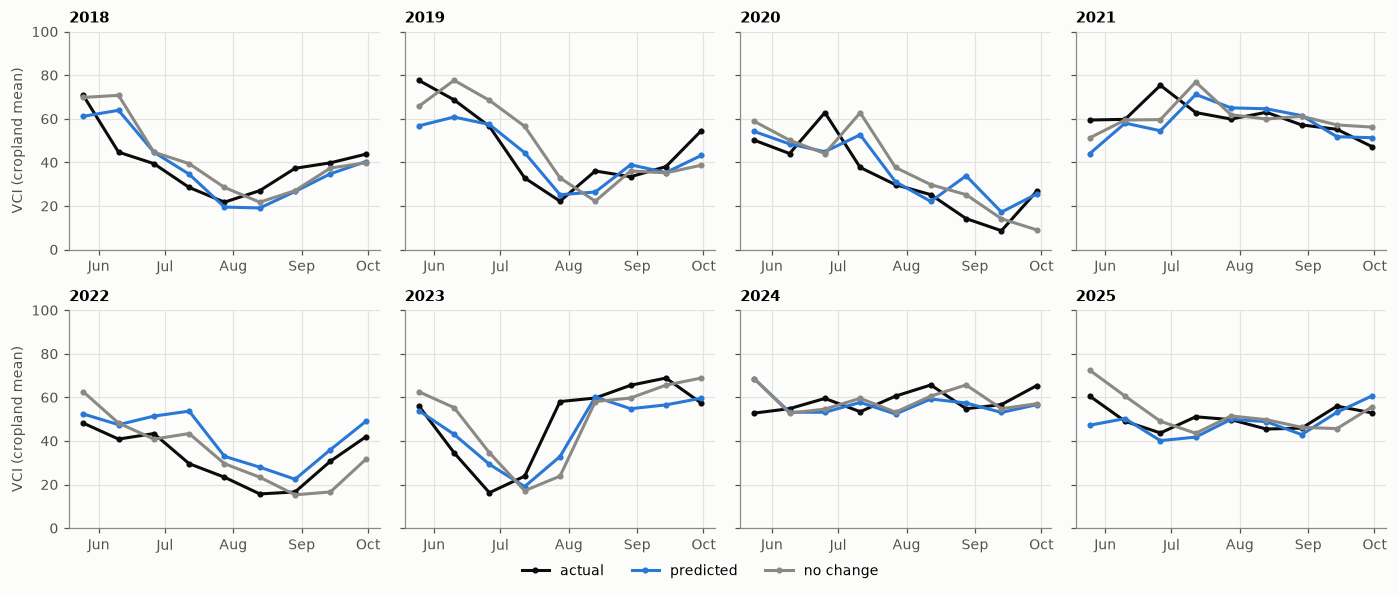

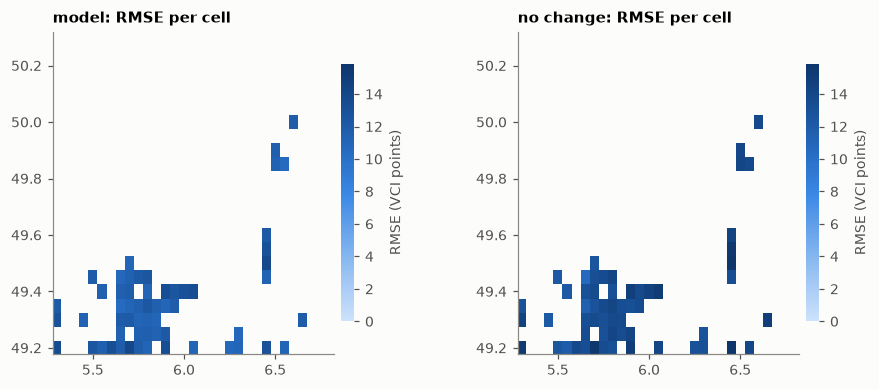

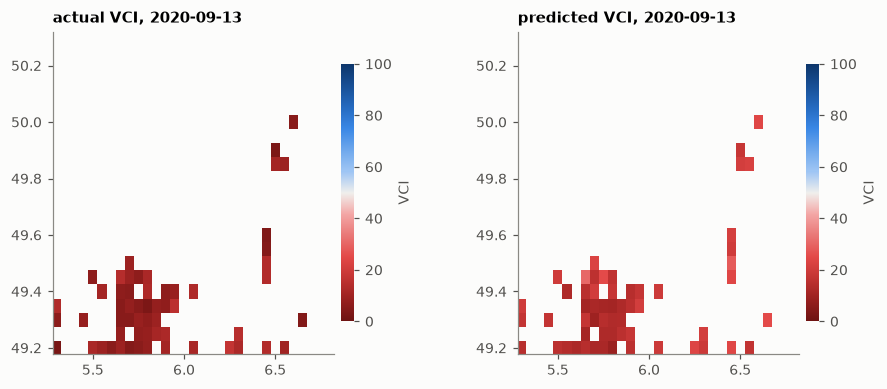

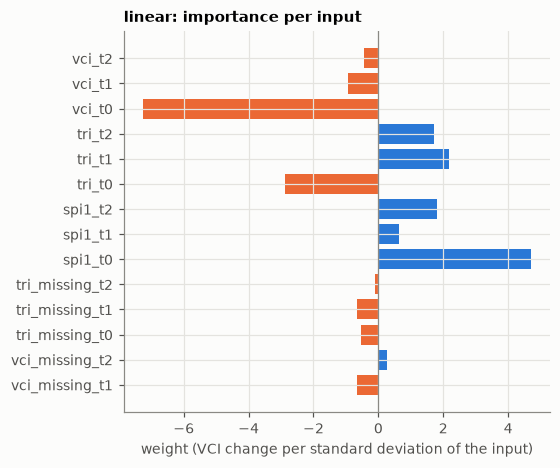

RMSE over all seasons: linear 11.9, no change 13.7; better in 6 of 8 seasons
cropland-mean RMSE: linear 9.6, no change 11.1
better than no change in 57 of 58 cells; RMSE per cell 10.4–14.0 (no change 10.7–15.9)
driest window 2020-09-13: cropland mean actual 8.7, linear 17.2, no change 14.1
largest importance: vci_t0 -7.3, spi1_t0 +4.7, tri_t0 -2.9


In [11]:
show_model("linear")

- **Over the season:** the no-change line is roughly the actual line shifted one window later. The model partly makes up for that lag (cropland-mean RMSE 9.6 against 11.1).
- **In space:** better than no change in 57 of the 58 cells, so the gain is not limited to one area (RMSE per cell 10.4–14.0, no change 10.7–15.9).
- **Driest window (13 Sep 2020):** actual VCI fell to 8.7 (cropland mean), but the model predicted 17.2, a rise from 14.1 in the window before. It learnt that a low VCI usually rises, and here the drought went on.
- **Importance:** VCI at t has the largest weight (−7.3): a high VCI now tends to drop next. SPI-1 at t comes second (+4.7): after a wet month VCI rises. TRI has a negative weight at t (−2.9) and positive weights at t−1 and t−2. Inputs that move together share one effect, so their weights should not be read one by one.

#### Gradient boosting (GBM)

`HistGradientBoostingRegressor` with the settings in `configs/gbm.yaml`; it handles missing values itself. Importance: how much the RMSE grows, in VCI points, when one input is shuffled.

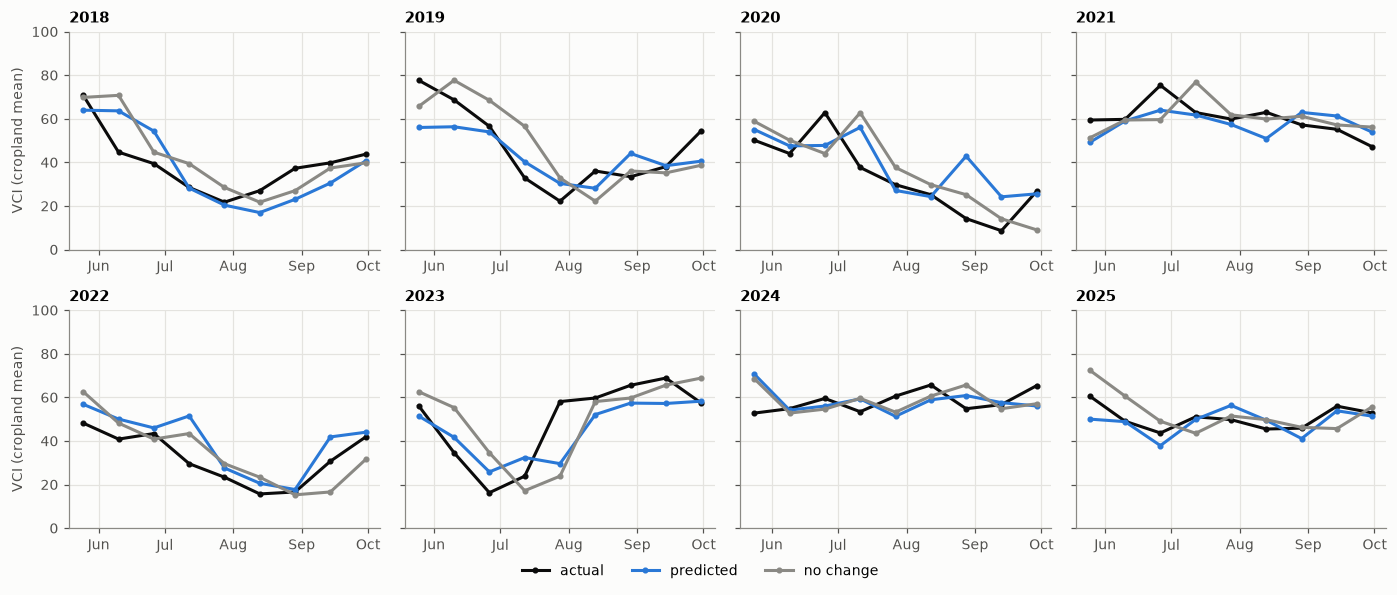

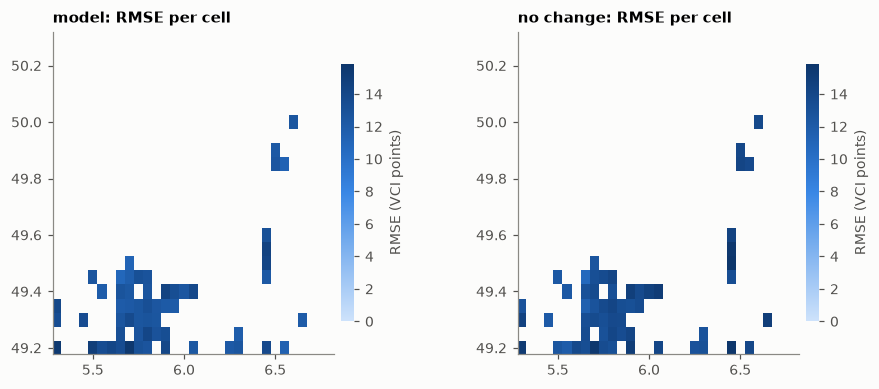

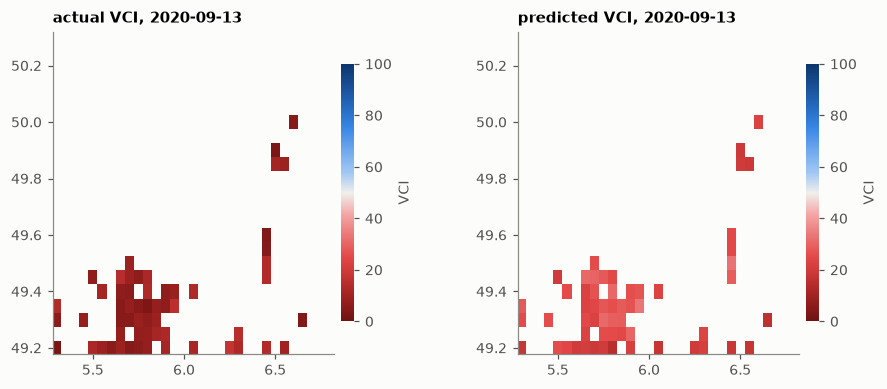

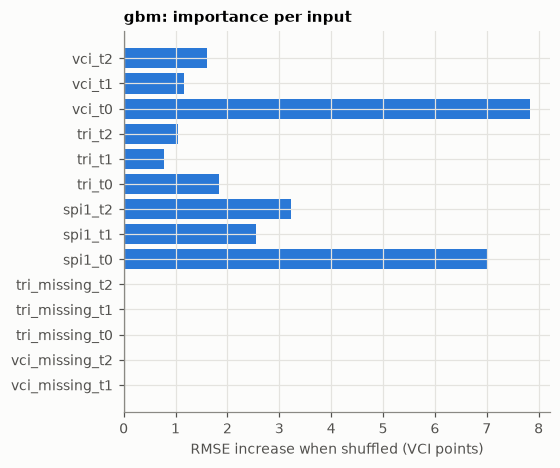

RMSE over all seasons: gbm 13.0, no change 13.7; better in 5 of 8 seasons
cropland-mean RMSE: gbm 10.1, no change 11.1
better than no change in 46 of 58 cells; RMSE per cell 10.9–15.7 (no change 10.7–15.9)
driest window 2020-09-13: cropland mean actual 8.7, gbm 24.2, no change 14.1
largest importance: vci_t0 +7.8, spi1_t0 +7.0, spi1_t2 +3.2


In [12]:
show_model("gbm")

- **Over the season:** closer to the actual line than no change (cropland-mean RMSE 10.1 against 11.1), but less close than linear (9.6). At the end of summer 2020 it predicted a clear rise while VCI kept falling.
- **In space:** better than no change in 46 of the 58 cells (RMSE per cell 10.9–15.7, no change 10.7–15.9).
- **Driest window (13 Sep 2020):** it predicted 24.2 against an actual 8.7, further off than linear (17.2) and no change (14.1).
- **Importance:** like linear, it relies most on VCI at t and SPI-1 at t (RMSE +7.8 and +7.0 when shuffled), then SPI-1 at t−2 (+3.2). The missing-value flags get no importance because GBM handles missing values itself.

## Future Work

Validation:                                    
- compare TRI with ECOSTRESS plant stress (high TRI -> high stress)
- compare VCI and the predictions with the EDO CDI levels (low VCI -> Alert)

More models:
- LSTM
- RNN
- Domain specific models discussed in [1]

More data:
- increase scale
- data augmentation

Feature engineering:
- add time feature: which part of the season is it, which year is it?
- other indices such as SPEI

Parameter tuning:
- how many time steps is optimal?



# Bibliography

- [1] Aldo Márquez-Grajales, Ramiro Villegas-Vega, Fernando Salas-Martínez, Héctor-Gabriel Acosta-Mesa, Efrén Mezura-Montes,
Characterizing drought prediction with deep learning: A literature review,
MethodsX,
Volume 13,
2024,
102800,
ISSN 2215-0161,
https://doi.org/10.1016/j.mex.2024.102800.
(https://www.sciencedirect.com/science/article/pii/S221501612400253X)

- [2] Trigo, I. F., et al. (2011). The Satellite Application Facility for Land Surface Analysis. International Journal of Remote Sensing, 32(10), 2725–2744. https://doi.org/10.1080/01431161003743199 (MSG LST)                                                      
- [3] Muñoz-Sabater, J., et al. (2021). ERA5-Land: a state-of-the-art global reanalysis dataset for land applications. Earth System Science Data, 13(9), 4349–4383. https://doi.org/10.5194/essd-13-4349-2021
- [4] Didan, K. (2021). MODIS/Terra Vegetation Indices 16-Day L3 Global 250m SIN Grid V061 (MOD13Q1). NASA LP DAAC. https://doi.org/10.5067/MODIS/MOD13Q1.061
- [5] Zanaga, D., et al. (2022). ESA WorldCover 10 m 2021 v200. Zenodo. https://doi.org/10.5281/zenodo.7254221
- [6] Hook, S., & Hulley, G. (2022). ECOSTRESS Tiled Land Surface Temperature and Emissivity Instantaneous L2 Global 70 m V002. NASA LP DAAC. https://doi.org/10.5067/ECOSTRESS/ECO_L2T_LSTE.002     
- [7] Cammalleri, C., et al. (2021). A revision of the Combined Drought Indicator (CDI) used in the European Drought Observatory (EDO). Natural Hazards and Earth System Sciences, 21(2), 481–495. https://doi.org/10.5194/nhess-21-481-2021
- [8] Kogan, F. N. (1995). Application of vegetation index and brightness temperature for drought detection. Advances in Space Research, 15(11), 91–100. https://doi.org/10.1016/0273-1177(95)00079-T (VCI)
- [9] McKee, T. B., Doesken, N. J., & Kleist, J. (1993). The relationship of drought frequency and duration to time scales. Proceedings of the 8th Conference on Applied Climatology, Anaheim, CA, 179–184. (SPI) 